# GHSOM + GNG Neuro-Symbolic Pipeline: run and test

This notebook must sit in the `ghsom_gng_ns` folder (where it is when you unzip the package).
Open it with **Jupyter Notebook**, **JupyterLab**, **VS Code** or **Anaconda Navigator**, then run the cells from top to bottom.

* Sections 1–3 take about a minute: install, quick Kaggle run, and testing single patients.
* Section 4 is the full experiment (both datasets, parameter sweeps, figures) and takes a few minutes.

Every run is seeded, so you should get the same numbers shown here.

## 1. Install the libraries (once)

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
for f in ["data/Training.csv", "data/ddxplus/release_test_patients.csv.gz",
          "data/rules/independent_rules.csv", "data/rules/ddxplus_rules.csv"]:
    print(("OK      " if os.path.exists(f) else "MISSING ") + f)

OK      data/Training.csv
OK      data/ddxplus/release_test_patients.csv.gz
OK      data/rules/independent_rules.csv
OK      data/rules/ddxplus_rules.csv


## 2. Quick run on Kaggle
`train.py` trains 10 models (seeds 0–9). Each holds out 4 diseases as "new": they are removed from training and from the ontology.
`test.py` streams the test patients through 4 systems and prints the results (mean ± sd over the 10 models).

In [3]:
%run train.py --datasets kaggle


=== kaggle: 304 patients, 131 features, 41 diseases
  seed 0: GHSOM 8 maps, depth 2, 37 leaf clusters (purity 0.970); GNG 37 nodes; CART fidelity 0.327; held out ['Diabetes', 'Hepatitis C', 'Hyperthyroidism', 'Paralysis (brain hemorrhage)']; 0.1s
  seed 1: GHSOM 11 maps, depth 3, 39 leaf clusters (purity 0.962); GNG 39 nodes; CART fidelity 0.278; held out ['Hemorrhoids (piles)', 'Hepatitis B', 'Migraine', 'Typhoid']; 0.1s


  seed 2: GHSOM 10 maps, depth 3, 37 leaf clusters (purity 0.962); GNG 37 nodes; CART fidelity 0.321; held out ['Arthritis', 'Dengue', 'Drug Reaction', 'Osteoarthritis']; 0.1s
  seed 3: GHSOM 13 maps, depth 3, 41 leaf clusters (purity 0.985); GNG 41 nodes; CART fidelity 0.259; held out ['Allergy', 'Chicken pox', 'Common Cold', 'Migraine']; 0.1s
  seed 4: GHSOM 11 maps, depth 3, 39 leaf clusters (purity 1.000); GNG 39 nodes; CART fidelity 0.393; held out ['Hepatitis C', 'Impetigo', 'Pneumonia', 'Psoriasis']; 0.1s


  seed 5: GHSOM 9 maps, depth 3, 37 leaf clusters (purity 0.939); GNG 37 nodes; CART fidelity 0.321; held out ['AIDS', 'Hypoglycemia', 'Osteoarthritis', 'Paroxysmal positional vertigo']; 0.1s
  seed 6: GHSOM 12 maps, depth 3, 40 leaf clusters (purity 0.978); GNG 40 nodes; CART fidelity 0.263; held out ['GERD', 'Heart attack', 'Hepatitis C', 'Urinary tract infection']; 0.1s
  seed 7: GHSOM 10 maps, depth 3, 34 leaf clusters (purity 0.931); GNG 34 nodes; CART fidelity 0.327; held out ['Hyperthyroidism', 'Impetigo', 'Pneumonia', 'Psoriasis']; 0.1s


  seed 8: GHSOM 11 maps, depth 2, 40 leaf clusters (purity 0.977); GNG 40 nodes; CART fidelity 0.345; held out ['Common Cold', 'Drug Reaction', 'Impetigo', 'Varicose veins']; 0.1s
  seed 9: GHSOM 9 maps, depth 3, 37 leaf clusters (purity 0.992); GNG 37 nodes; CART fidelity 0.291; held out ['Diabetes', 'Heart attack', 'Paroxysmal positional vertigo', 'Typhoid']; 0.1s


In [4]:
%run test.py --datasets kaggle --no-sweep

evaluated kaggle_seed0.pkl


evaluated kaggle_seed1.pkl


evaluated kaggle_seed2.pkl


evaluated kaggle_seed3.pkl


evaluated kaggle_seed4.pkl


evaluated kaggle_seed5.pkl


evaluated kaggle_seed6.pkl


evaluated kaggle_seed7.pkl


evaluated kaggle_seed8.pkl


evaluated kaggle_seed9.pkl

RESULTS (mean ± sd over seeds)

dataset                                     kaggle                                                                                                                                                                         
method                    Neural-alone (GHSOM+GNG) Neural-alone, strict GNG Neuro-symbolic (full) Supervised: logistic regression Supervised: random forest Supervised: random forest + confidence threshold Symbolic-alone
known_accuracy                       0.950 ± 0.036            0.941 ± 0.036         0.969 ± 0.020                   1.000 ± 0.000             1.000 ± 0.000                                    0.935 ± 0.040  0.596 ± 0.041
known_macro_f1                       0.925 ± 0.053            0.920 ± 0.048         0.969 ± 0.023                   1.000 ± 0.000             1.000 ± 0.000                                    0.943 ± 0.037  0.585 ± 0.041
known_false_new_rate                 0.000 ± 0.000          

## 3. Test single patients
`diagnose.py` shows what each stage does for one patient.
The demo runs one known-disease patient, then patients of a disease the pipeline has never seen (Case 1, then Case 2, then Case 3).

In [5]:
%run diagnose.py --demo

DEMO: one known-disease patient, then patients of 'Hyperthyroidism', a disease the pipeline never saw (held out of training and of the ontology).
(This held-out disease was picked because its first patient is flagged as new, to show Cases 2 and 3. Not every new-disease patient is caught - see results/ for the rates. Use --novel "<name>" to try another.)

PATIENT 1: stomach_pain, acidity, ulcers_on_tongue, vomiting, chest_pain   [true disease: GERD]
------------------------------------------------------------------------------
STAGE 1  GHSOM -> cluster 21 (trained label: GERD, purity 1.00)
         error within cluster range? YES (conformal p = 0.536 > alpha 0.05)
STAGE 2  FIT EXPLANATION
         top deviating symptoms: cough (expected for cluster, absent), stomach_pain (present, unusual for cluster), vomiting (present, unusual for cluster)
         CART rule (for human readers, fidelity 0.33): NOT pain_behind_the_eyes AND NOT red_spots_over_body AND NOT visual_disturbances AND NOT thr

In [6]:
# Which diseases does this model know, and which were held out as 'new'?
%run diagnose.py --list-diseases

KNOWN (trained, in the ontology):
  AIDS
  Acne
  Alcoholic hepatitis
  Allergy
  Arthritis
  Bronchial Asthma
  Cervical spondylosis
  Chicken pox
  Chronic cholestasis
  Common Cold
  Dengue
  Drug Reaction
  Fungal infection
  GERD
  Gastroenteritis
  Heart attack
  Hemorrhoids (piles)
  Hepatitis A
  Hepatitis B
  Hepatitis D
  Hepatitis E
  Hypertension
  Hypoglycemia
  Hypothyroidism
  Impetigo
  Jaundice
  Malaria
  Migraine
  Osteoarthritis
  Paroxysmal positional vertigo
  Peptic ulcer disease
  Pneumonia
  Psoriasis
  Tuberculosis
  Typhoid
  Urinary tract infection
  Varicose veins

HELD OUT (the pipeline has never seen these - they should come out as NEW):
  Diabetes
  Hepatitis C
  Hyperthyroidism
  Paralysis (brain hemorrhage)


### Your own patients
Type symptom names separated by commas (`%run diagnose.py --list-symptoms` prints all 131 names).
Give several `--patient` options to run patients in order: the GNG and the new-disease list carry over between them,
so the second patient of an unknown disease can be recognised as the same new disease (Case 3).

In [7]:
%run diagnose.py --patient "itching,skin_rash,nodal_skin_eruptions,dischromic_patches"

PATIENT 1: itching, skin_rash, nodal_skin_eruptions, dischromic_patches
------------------------------------------------------------------------------
STAGE 1  GHSOM -> cluster 11 (trained label: Fungal infection, purity 0.50)
         error within cluster range? YES (conformal p = 0.071 > alpha 0.05)
STAGE 2  FIT EXPLANATION
         top deviating symptoms: itching (present, unusual for cluster), nodal_skin_eruptions (present, unusual for cluster), dischromic_patches (present, unusual for cluster)
         CART rule (for human readers, fidelity 0.33): NOT pain_behind_the_eyes AND NOT red_spots_over_body AND NOT visual_disturbances AND NOT throat_irritation AND NOT abnormal_menstruation AND NOT palpi
STAGE 3  ONTOLOGY -> Ontology reasoning (low purity): ontology score 0.50 >= theta 0.29
         ontology ranking: Fungal infection 0.50 (needs 0.29), Urinary tract infection 0.00 (needs 0.31)

>>> RESULT: KNOWN disease: Fungal infection


In [8]:
# Two patients with hyperthyroid symptoms (Hyperthyroidism is held out of this model)
%run diagnose.py --patient "fatigue,weight_loss,restlessness,sweating,diarrhoea,fast_heart_rate,excessive_hunger,muscle_weakness,irritability,abnormal_menstruation" --patient "fatigue,mood_swings,weight_loss,sweating,diarrhoea,fast_heart_rate,excessive_hunger,muscle_weakness,irritability,abnormal_menstruation"

PATIENT 1: fatigue, weight_loss, restlessness, sweating, diarrhoea, fast_heart_rate, excessive_hunger, muscle_weakness, irritability, abnormal_menstruation
------------------------------------------------------------------------------
STAGE 1  GHSOM nearest cluster 27 -> error OUT of range (p = 0.036 <= 0.05) -> OUTLIER, sent to GNG
         GNG: accepted by node(s): #15 Hypoglycemia (p=0.05), #14 Pneumonia (p=0.04), #26 Hypothyroidism (p=0.04)
STAGE 2  PROXIMITY EXPLANATION
         vs node #15 Hypoglycemia: shares 4, lacks ['vomiting', 'anxiety', 'headache', 'nausea'], extra ['weight_loss', 'restlessness', 'diarrhoea', 'fast_heart_rate'] (Hamming 14)
         vs node #14 Pneumonia: shares 3, lacks ['chills', 'cough', 'high_fever', 'breathlessness'], extra ['weight_loss', 'restlessness', 'diarrhoea', 'excessive_hunger'] (Hamming 15)
STAGE 3  ONTOLOGY -> Case 2: no known disease or earlier addition fits
         ontology ranking: Hypoglycemia 0.45 (needs 0.61), Tuberculosis 0.27 (needs

## 4. Full experiment: both datasets, parameter sweeps, figures (a few minutes)

In [9]:
%run train.py


=== kaggle: 304 patients, 131 features, 41 diseases
  seed 0: GHSOM 8 maps, depth 2, 37 leaf clusters (purity 0.970); GNG 37 nodes; CART fidelity 0.327; held out ['Diabetes', 'Hepatitis C', 'Hyperthyroidism', 'Paralysis (brain hemorrhage)']; 0.1s
  seed 1: GHSOM 11 maps, depth 3, 39 leaf clusters (purity 0.962); GNG 39 nodes; CART fidelity 0.278; held out ['Hemorrhoids (piles)', 'Hepatitis B', 'Migraine', 'Typhoid']; 0.1s


  seed 2: GHSOM 10 maps, depth 3, 37 leaf clusters (purity 0.962); GNG 37 nodes; CART fidelity 0.321; held out ['Arthritis', 'Dengue', 'Drug Reaction', 'Osteoarthritis']; 0.1s
  seed 3: GHSOM 13 maps, depth 3, 41 leaf clusters (purity 0.985); GNG 41 nodes; CART fidelity 0.259; held out ['Allergy', 'Chicken pox', 'Common Cold', 'Migraine']; 0.1s
  seed 4: GHSOM 11 maps, depth 3, 39 leaf clusters (purity 1.000); GNG 39 nodes; CART fidelity 0.393; held out ['Hepatitis C', 'Impetigo', 'Pneumonia', 'Psoriasis']; 0.1s


  seed 5: GHSOM 9 maps, depth 3, 37 leaf clusters (purity 0.939); GNG 37 nodes; CART fidelity 0.321; held out ['AIDS', 'Hypoglycemia', 'Osteoarthritis', 'Paroxysmal positional vertigo']; 0.1s
  seed 6: GHSOM 12 maps, depth 3, 40 leaf clusters (purity 0.978); GNG 40 nodes; CART fidelity 0.263; held out ['GERD', 'Heart attack', 'Hepatitis C', 'Urinary tract infection']; 0.1s
  seed 7: GHSOM 10 maps, depth 3, 34 leaf clusters (purity 0.931); GNG 34 nodes; CART fidelity 0.327; held out ['Hyperthyroidism', 'Impetigo', 'Pneumonia', 'Psoriasis']; 0.1s


  seed 8: GHSOM 11 maps, depth 2, 40 leaf clusters (purity 0.977); GNG 40 nodes; CART fidelity 0.345; held out ['Common Cold', 'Drug Reaction', 'Impetigo', 'Varicose veins']; 0.1s
  seed 9: GHSOM 9 maps, depth 3, 37 leaf clusters (purity 0.992); GNG 37 nodes; CART fidelity 0.291; held out ['Diabetes', 'Heart attack', 'Paroxysmal positional vertigo', 'Typhoid']; 0.1s



=== ddxplus: 1943 patients, 426 features, 49 diseases


  seed 0: GHSOM 20 maps, depth 3, 68 leaf clusters (purity 0.968); GNG 68 nodes; CART fidelity 0.236; held out ['Bronchiolitis', 'Chagas', 'Influenza', 'Myocarditis', 'SLE']; 0.7s


... (5 outputs left out)

  seed 6: GHSOM 23 maps, depth 3, 73 leaf clusters (purity 0.980); GNG 73 nodes; CART fidelity 0.256; held out ['Chronic rhinosinusitis', 'Epiglottitis', 'Influenza', 'Unstable angina', 'Whooping cough']; 0.8s


  seed 7: GHSOM 20 maps, depth 3, 66 leaf clusters (purity 0.968); GNG 66 nodes; CART fidelity 0.305; held out ['Myasthenia gravis', 'Panic attack', 'Spontaneous rib fracture', 'Stable angina', 'Whooping cough']; 0.7s


  seed 8: GHSOM 21 maps, depth 3, 67 leaf clusters (purity 0.959); GNG 67 nodes; CART fidelity 0.331; held out ['Anemia', 'Bronchiectasis', 'Chagas', 'Panic attack', 'Viral pharyngitis']; 0.7s


  seed 9: GHSOM 17 maps, depth 3, 61 leaf clusters (purity 0.975); GNG 61 nodes; CART fidelity 0.243; held out ['Acute rhinosinusitis', 'Bronchitis', 'Croup', 'Scombroid food poisoning', 'URTI']; 0.7s


In [10]:
%run test.py

evaluated kaggle_seed0.pkl


evaluated kaggle_seed1.pkl


evaluated kaggle_seed2.pkl


evaluated kaggle_seed3.pkl


evaluated kaggle_seed4.pkl


evaluated kaggle_seed5.pkl


... (10 outputs left out)

evaluated ddxplus_seed6.pkl


evaluated ddxplus_seed7.pkl


evaluated ddxplus_seed8.pkl


evaluated ddxplus_seed9.pkl

RESULTS (mean ± sd over seeds)

dataset                                    ddxplus                                                                                                                                                                                            kaggle                                                                                                                                                                         
method                    Neural-alone (GHSOM+GNG) Neural-alone, strict GNG Neuro-symbolic (full) Supervised: logistic regression Supervised: random forest Supervised: random forest + confidence threshold Symbolic-alone Neural-alone (GHSOM+GNG) Neural-alone, strict GNG Neuro-symbolic (full) Supervised: logistic regression Supervised: random forest Supervised: random forest + confidence threshold Symbolic-alone
known_accuracy                       0.952 ± 0.015            0.941 ± 0.015         0.953 ± 0.015              

In [11]:
%run supervised_ceiling.py

   dataset                      model                                         scored_by  accuracy  precision  recall     f1   top3
0   kaggle        Logistic regression                           5-fold cross-validation     1.000      1.000    1.00  1.000  1.000
1   kaggle  Random forest (300 trees)                           5-fold cross-validation     1.000      1.000    1.00  1.000  1.000
2  ddxplus        Logistic regression  trained on 18,757-patient pool, tested on sample     0.973      0.961    0.97  0.964  0.982
3  ddxplus  Random forest (300 trees)  trained on 18,757-patient pool, tested on sample     0.973      0.960    0.97  0.964  0.982


In [12]:
%run per_disease.py

kaggle diseases 41 never held out: 16 | mean known recall 0.965 | recall 1.0: 33 | recall < 0.8: ['AIDS', 'Gastroenteritis']
ddxplus diseases 49 never held out: 17 | mean known recall 0.953 | recall 1.0: 18 | recall < 0.8: ['Chronic rhinosinusitis']


In [13]:
%run make_figures.py

figures written to results/figures


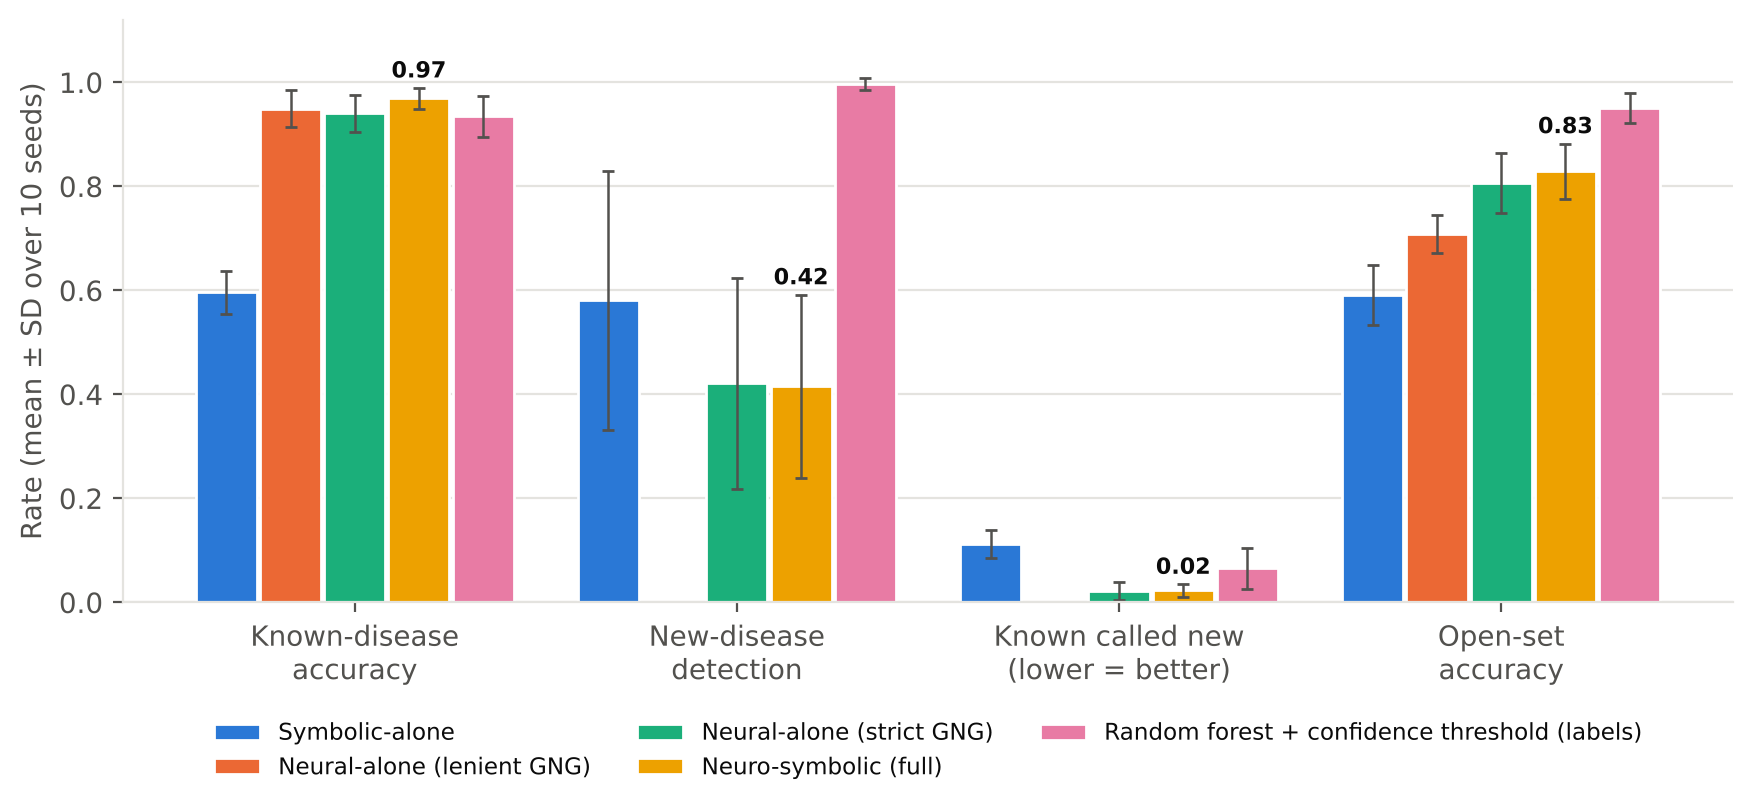

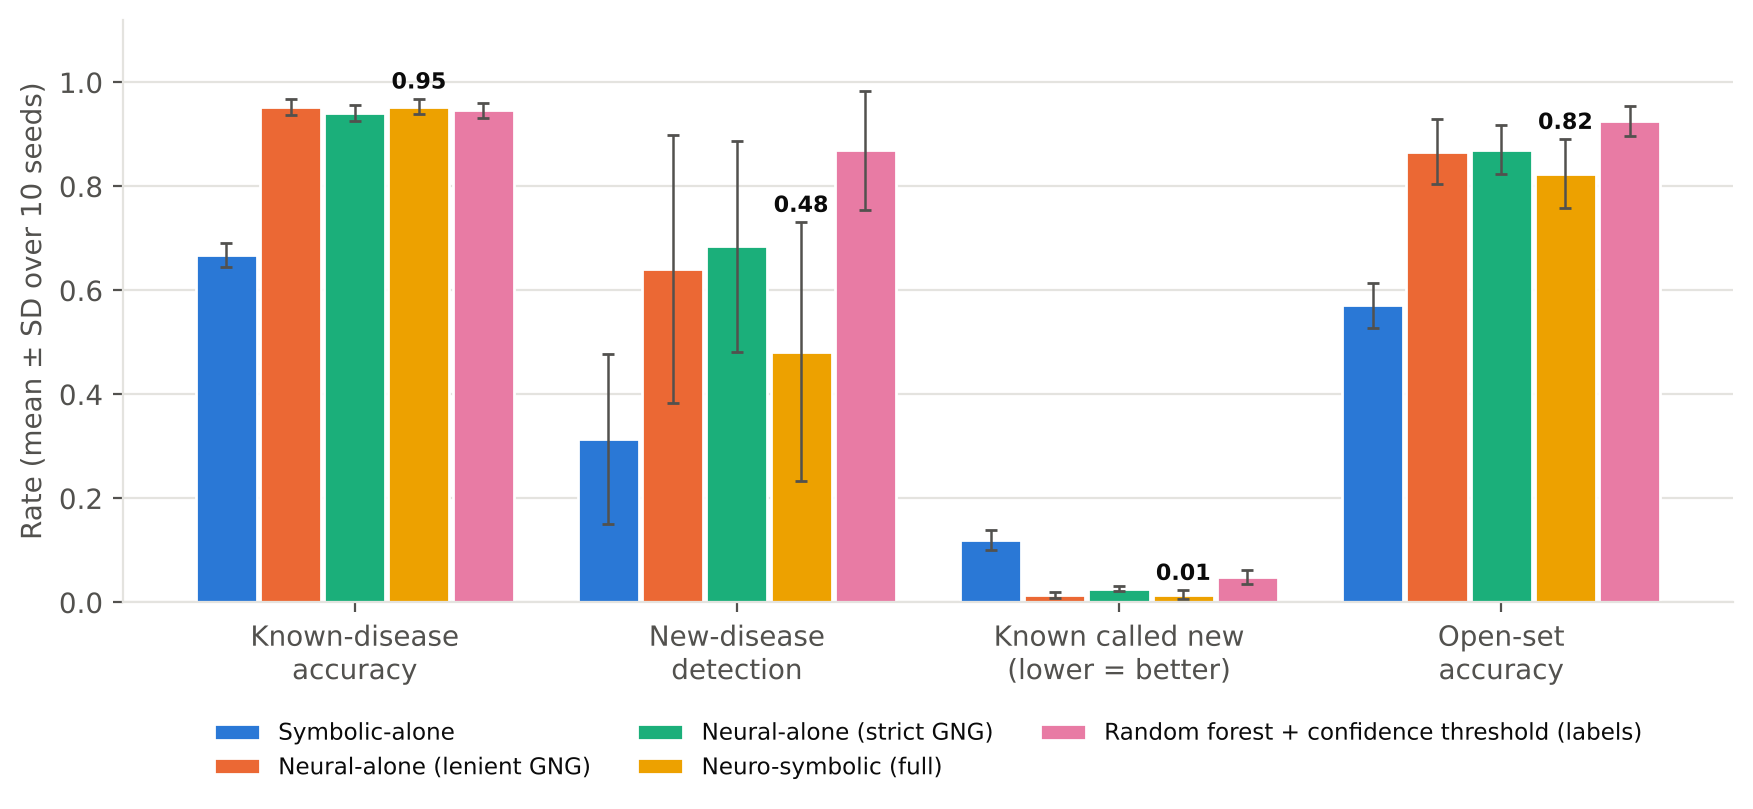

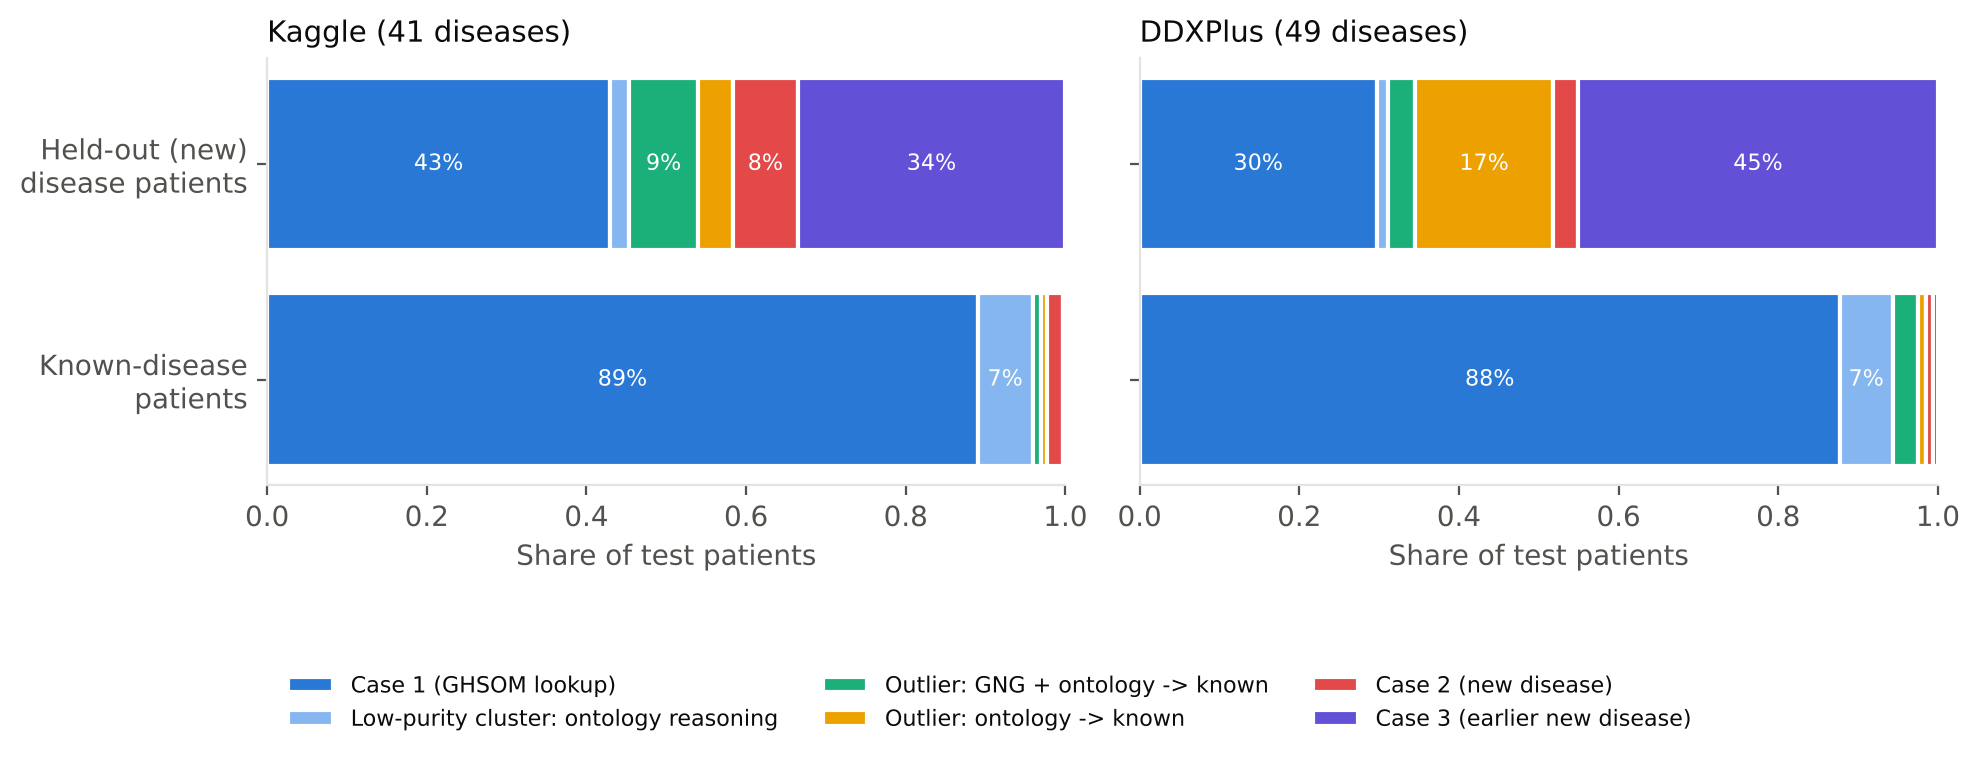

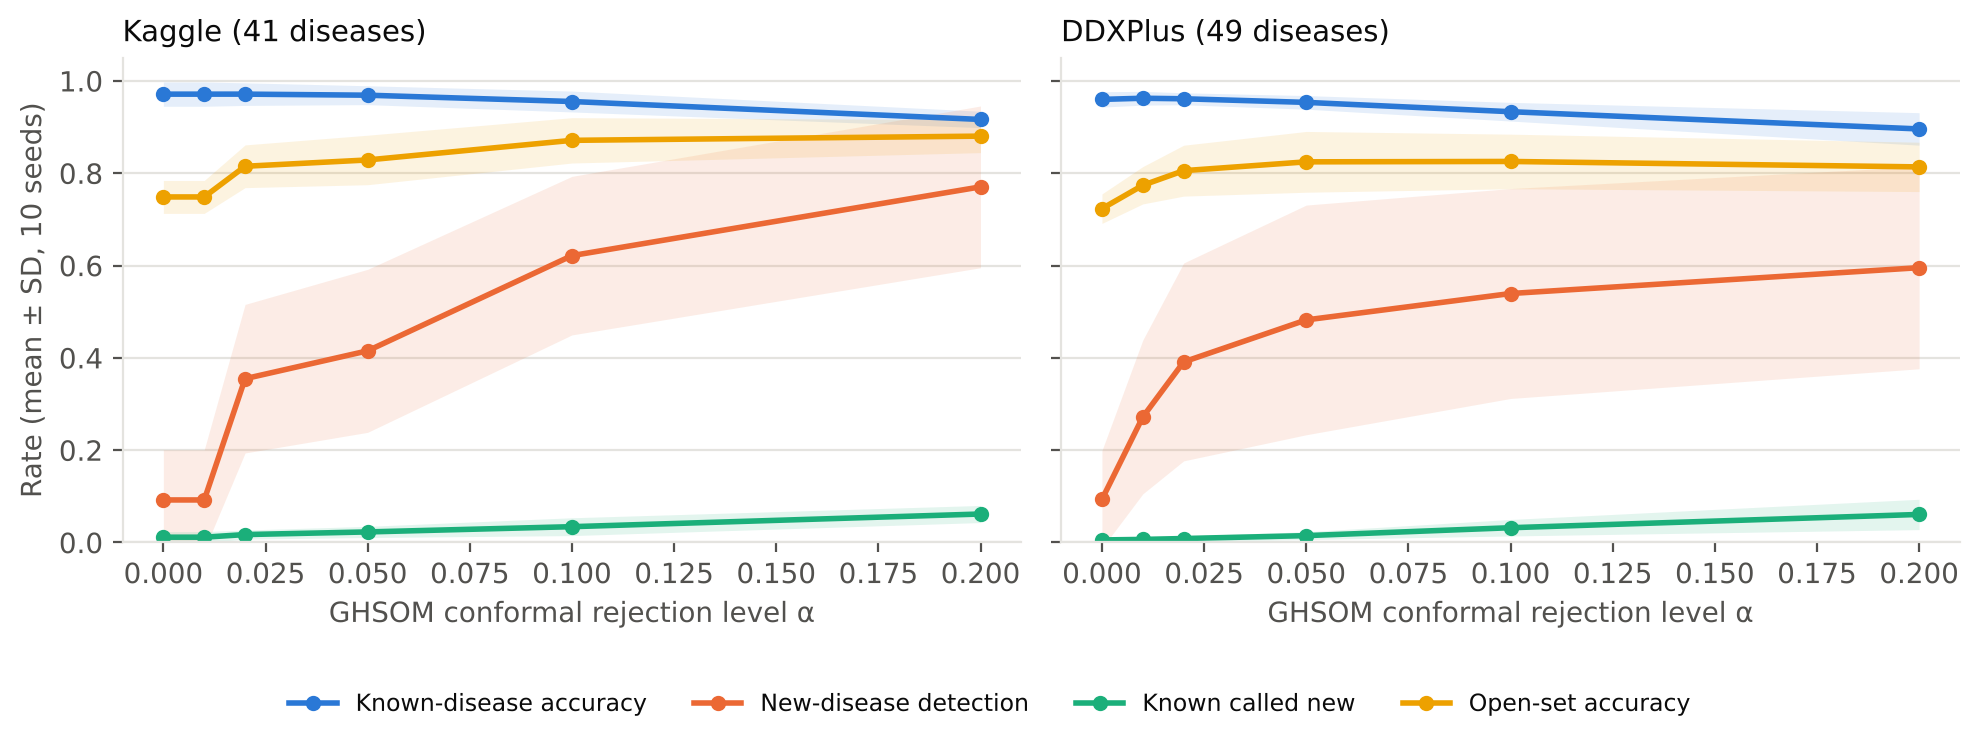

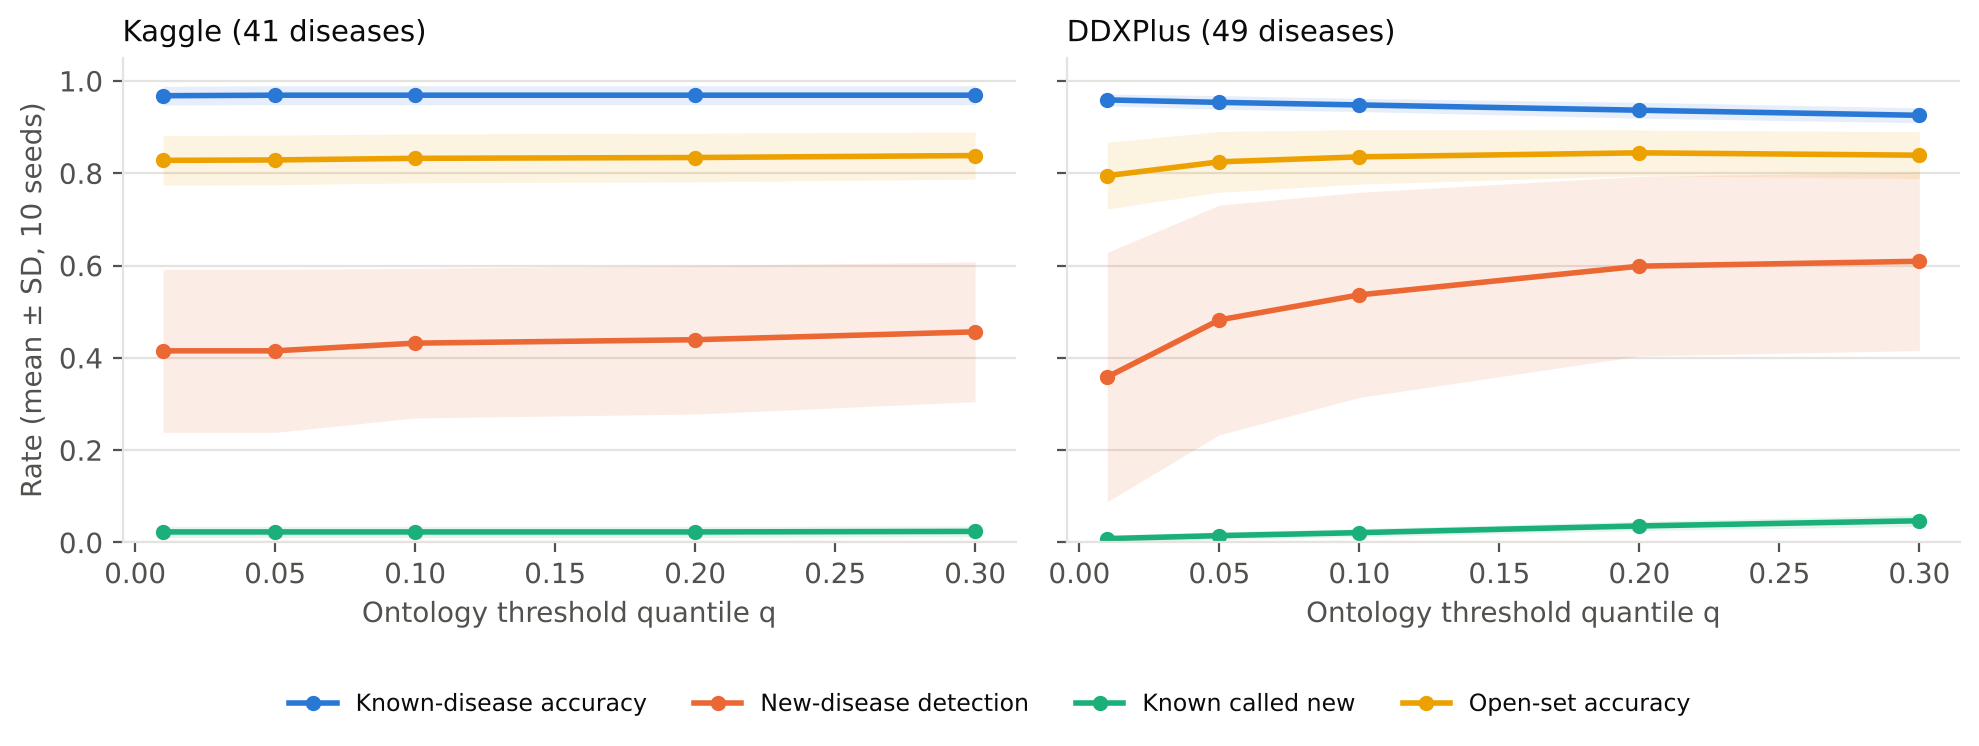

known_accuracy  novel_detection_rate  known_false_new_rate  open_set_accuracy
dataset method                                                                                                                         
ddxplus Neural-alone (GHSOM+GNG)                                   0.952                 0.640                 0.015              0.867
        Neural-alone, strict GNG                                   0.941                 0.684                 0.026              0.871
        Neuro-symbolic (full)                                      0.953                 0.482                 0.015              0.825
        Supervised: logistic regression                            0.989                 0.000                 0.000              0.719
        Supervised: random forest                                  0.987                 0.000                 0.000              0.717
        Supervised: random forest + confidence threshold           0.946                 0.869                 0.049              0.925
        Symbolic-alone                                             0.668                 0.314                 0.120              0.571
kaggle  Neural-alone (GHSOM+GNG)                                   0.950                 0.000                 0.000              0.709
        Neural-alone, strict GNG                                   0.941                 0.421                 0.022              0.807
        Neuro-symbolic (full)                                      0.969                 0.415                 0.023              0.829
        Supervised: logistic regression                            1.000                 0.000                 0.000              0.746
        Supervised: random forest                                  1.000                 0.000                 0.000              0.746
        Supervised: random forest + confidence threshold           0.935                 0.997                 0.065              0.951
        Symbolic-alone                                             0.596                 0.581                 0.112              0.591

In [14]:
from IPython.display import Image, display
import pandas as pd
display(Image("results/figures/fig_main_kaggle.png"))
display(Image("results/figures/fig_main_ddxplus.png"))
display(Image("results/figures/fig_routes.png"))
display(Image("results/figures/fig_alpha_fit_sweep.png"))
display(Image("results/figures/fig_ontology_q_sweep.png"))
(pd.read_csv("results/per_run.csv")
   .groupby(["dataset", "method"])[["known_accuracy", "novel_detection_rate", "known_false_new_rate", "open_set_accuracy"]]
   .mean().round(3))

In [15]:
# Try a DDXPlus patient (features are evidence codes; descriptions are in data/rules/ddxplus_feature_descriptions.csv)
%run diagnose.py --dataset ddxplus --demo

DEMO: one known-disease patient, then patients of 'Chagas', a disease the pipeline never saw (held out of training and of the ontology).
(This held-out disease was picked because its first patient is flagged as new, to show Cases 2 and 3. Not every new-disease patient is caught - see results/ for the rates. Use --novel "<name>" to try another.)

PATIENT 1: E_66, E_156, E_83, E_157, E_176, E_177, E_0, sex_male, age_65_plus   [true disease: Guillain-Barré syndrome]
------------------------------------------------------------------------------
STAGE 1  GHSOM -> cluster 7 (trained label: Guillain-Barré syndrome, purity 1.00)
         error within cluster range? YES (conformal p = 0.449 > alpha 0.05)
STAGE 2  FIT EXPLANATION
         top deviating symptoms: age_65_plus (present, unusual for cluster), E_84 (expected for cluster, absent), E_93 (expected for cluster, absent)
         CART rule (for human readers, fidelity 0.24): NOT E_187 AND NOT E_153 AND NOT E_178 AND NOT E_151 AND NOT E_3 A

## 5. Automated tests
Twenty checks of the code against the design (data cleaning, growth cap, Stage 3 reading only the explanation, and so on).

In [16]:
!python -m pytest -q test_pipeline.py

..

..

.

.............

...                                                    [100%]
21 passed in 6.38s
